In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import PolynomialFeatures
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso

from sklearn.pipeline import Pipeline

from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score


In [ ]:
data = {
    "x": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12],
    "y": [1.2, 3.8, 8.5, 15.2, 23.5, 36.5, 48.0, 64.5, 80.0, 101.5, 120.0, 145.5]
}

df = pd.DataFrame(data)

X = df [["x"]]
y = df ["y"]

print(df)

     x      y
0    1    1.2
1    2    3.8
2    3    8.5
3    4   15.2
4    5   23.5
5    6   36.5
6    7   48.0
7    8   64.5
8    9   80.0
9   10  101.5
10  11  120.0
11  12  145.5


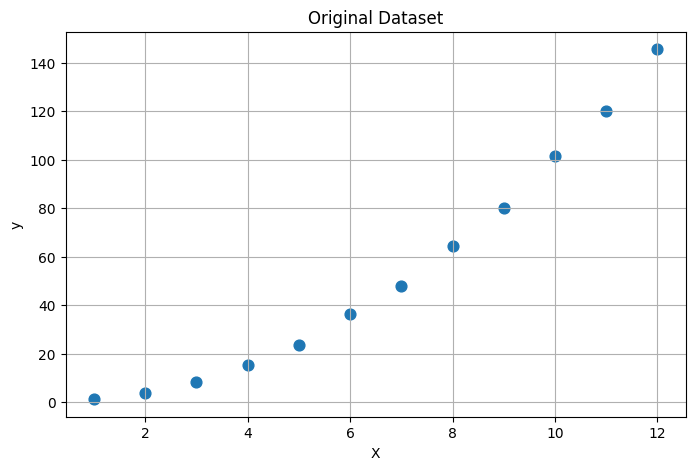

In [ ]:
plt.figure(figsize=(8,5))

plt.scatter(X, y, s=60)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Original Dataset")

plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


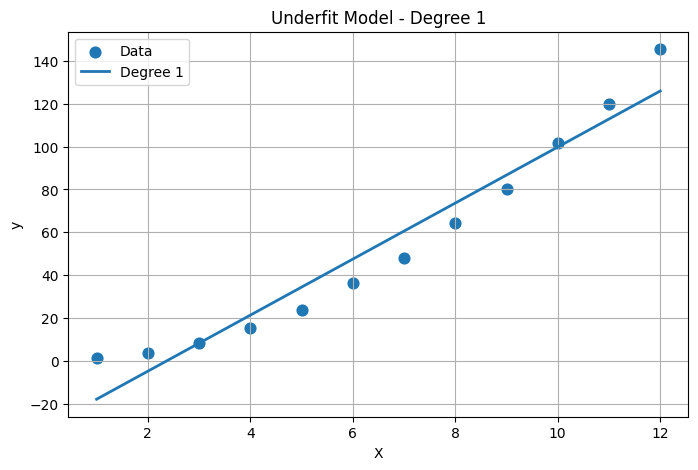

In [ ]:
model_underfit = Pipeline([
    ("poly", PolynomialFeatures(degree=1)),
    ("linear", LinearRegression())
])

model_underfit.fit(X, y)

x_plot = np.linspace(1, 12, 300).reshape(-1, 1)

y_pred_underfit = model_underfit.predict(x_plot)

plt.figure(figsize=(8,5))

plt.scatter(X, y, s=60, label="Data")

plt.plot(
    x_plot,
    y_pred_underfit,
    linewidth = 2,
    label = "Degree 1"
)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Underfit Model - Degree 1")

plt.legend()
plt.grid(True)
plt.show()


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


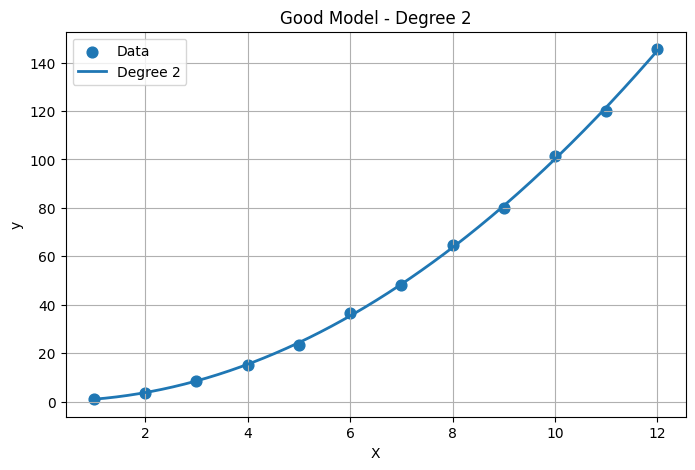

In [ ]:
model_good = Pipeline([
    ("poly", PolynomialFeatures(degree=2)),
    ("linear", LinearRegression())
])

model_good.fit(X, y)

y_pred_good = model_good.predict(x_plot)

plt.figure(figsize=(8,5))

plt.scatter(X, y, s=60, label="Data")

plt.plot(
    x_plot,
    y_pred_good,
    linewidth = 2,
    label = "Degree 2"
)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Good Model - Degree 2")

plt.legend()
plt.grid(True)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


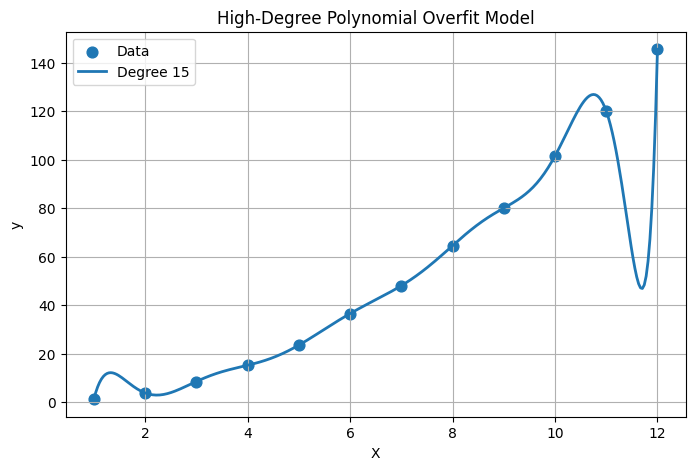

In [ ]:
model_overfit = Pipeline([
    ('poly', PolynomialFeatures(degree = 15)),
    ('scale', StandardScaler()),
    ('linear', LinearRegression())
])

model_overfit.fit(X, y)

y_pred_overfit = model_overfit.predict(x_plot)

plt.figure(figsize =(8,5))

plt.scatter(X, y, s=60, label = "Data")

plt.plot(
    x_plot,
    y_pred_overfit,
    linewidth = 2,
    label = "Degree 15"
)

plt.xlabel("X")
plt.ylabel("y")
plt.title("High-Degree Polynomial Overfit Model")

plt.legend()
plt.grid(True)
plt.show()

In [ ]:
#REGULARIZATION used in case of over fitting


# RIDGE Regularization = used when weights need to be shrinked

# LASSO Regularization = weights get shrinked to 0 ie removes a featurefeature when all are NOT imp

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


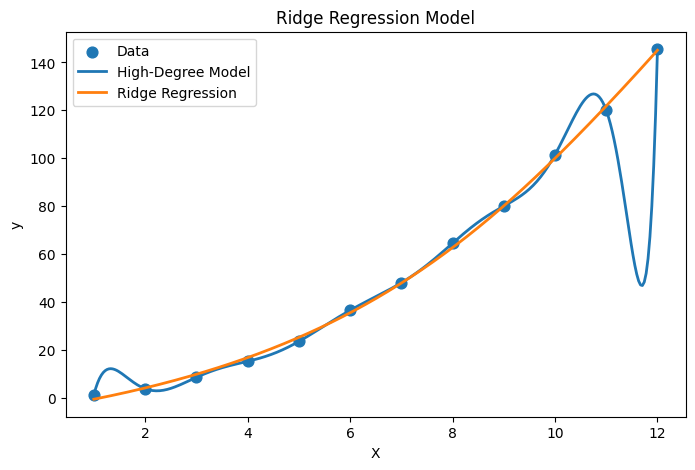

In [ ]:
ridge_model = Pipeline([
    ("poly", PolynomialFeatures(degree=15)),
    ("scale", StandardScaler()),
    ("ridge", Ridge(alpha=0.1))
])

ridge_model.fit(X,y)

y_pred_ridge = ridge_model.predict(x_plot)

plt.figure(figsize=(8,5))

plt.scatter(X, y, s=60, label='Data')

plt.plot(
    x_plot,
    y_pred_overfit,
    linewidth =2,
    label= "High-Degree Model"
)

plt.plot(
    x_plot,
    y_pred_ridge,
    linewidth =2,
    label= "Ridge Regression"
)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Ridge Regression Model")

plt.legend()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


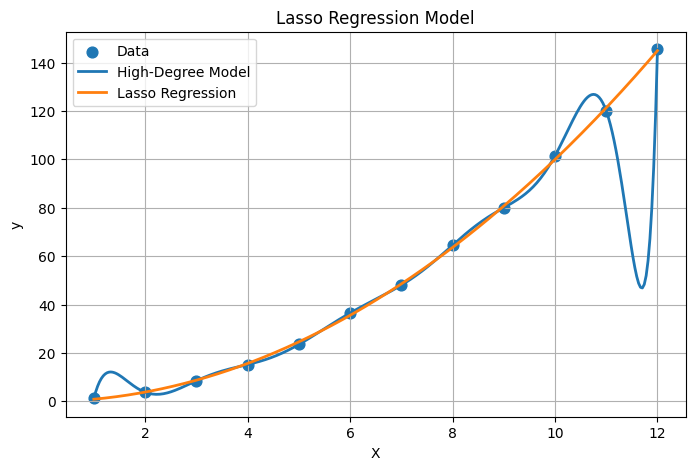

In [ ]:
lasso_model = Pipeline([
    ("ploy", PolynomialFeatures(degree=15)),
    ("scale", StandardScaler()),
    ("lasso", Lasso(alpha=0.1, max_iter = 100000))
])

lasso_model.fit(X,y)

y_pred_lasso = lasso_model.predict(x_plot)

plt.figure(figsize=(8,5))

plt.scatter(X, y, s=60, label='Data')

plt.plot(
    x_plot,
    y_pred_overfit,
    linewidth =2,
    label= "High-Degree Model"
)

plt.plot(
    x_plot,
    y_pred_lasso,
    linewidth = 2,
    label = "Lasso Regression"
)

plt.xlabel("X")
plt.ylabel("y")
plt.title("Lasso Regression Model")

plt.legend()
plt.grid(True)
plt.show()

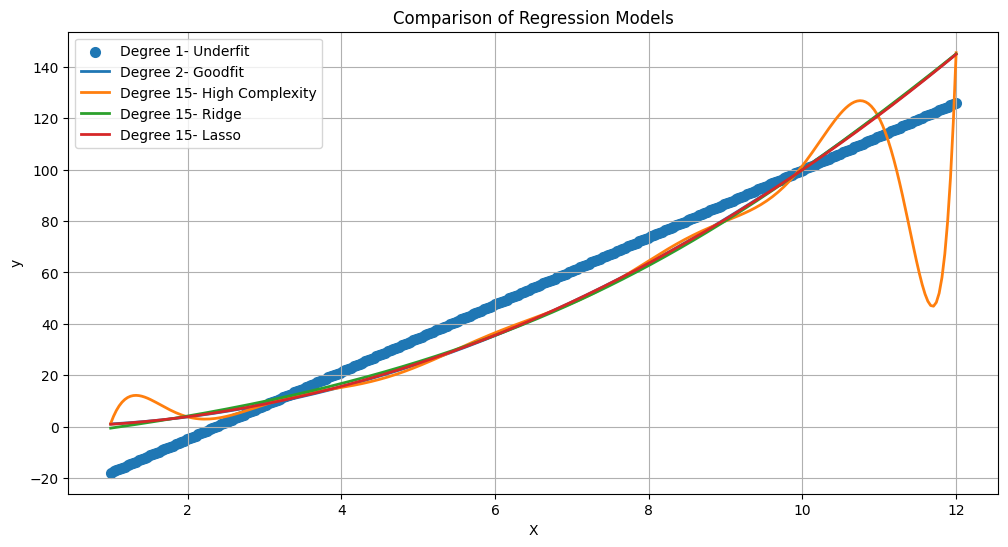

In [ ]:
#COMPARISON

plt.figure(figsize=(12,6))

plt.scatter(
    x_plot,
    y_pred_underfit,
    linewidth = 2,
    label = "Degree 1- Underfit"
)

plt.plot(
    x_plot,
    y_pred_good,
    linewidth=2,
    label= "Degree 2- Goodfit"
)

plt.plot(
    x_plot,
    y_pred_overfit,
    linewidth=2,
    label = "Degree 15- High Complexity"
)

plt.plot(
    x_plot,
    y_pred_ridge,
    linewidth=2,
    label ="Degree 15- Ridge "
)

plt.plot(
    x_plot,
    y_pred_lasso,
    linewidth=2,
    label ="Degree 15- Lasso"
)

plt.xlabel("X")
plt.ylabel('y')

plt.title('Comparison of Regression Models')

plt.legend()
plt.grid(True)
plt.show()